Image: bus.jpg  size=810×1080


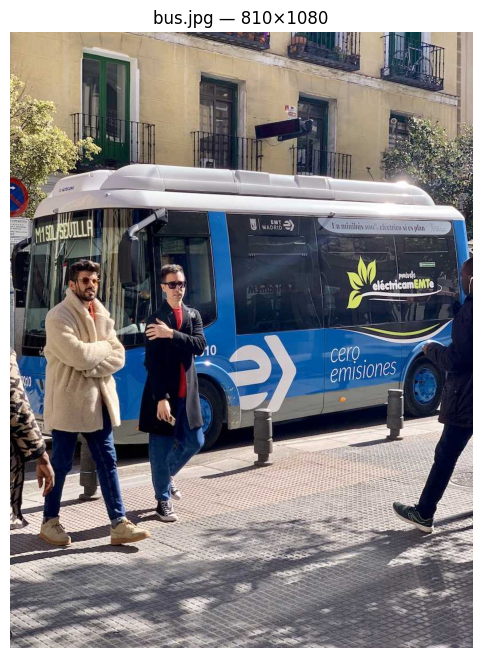

In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

img_path = Path("../data/bus.jpg")
img = cv2.imread(str(img_path))
if img is None:
    raise FileNotFoundError(f"Could not read {img_path.resolve()}")

H, W = img.shape[:2]
print(f"Image: {img_path.name}  size={W}×{H}")

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"bus.jpg — {W}×{H}")
plt.axis("off")
plt.show()

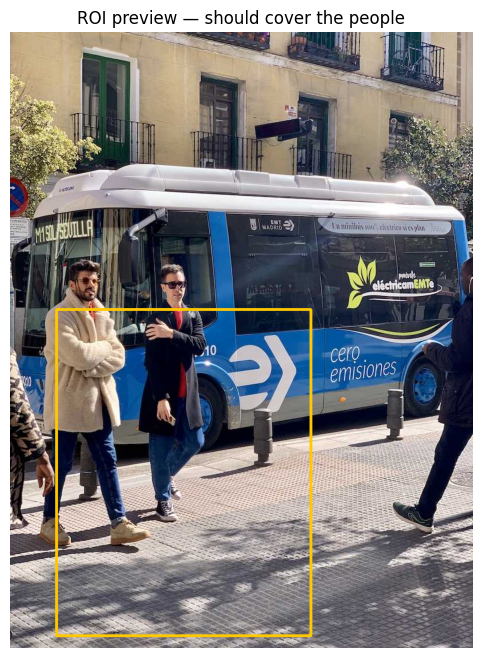

ROI: [[81, 486], [526, 486], [526, 1058], [81, 1058]]


In [2]:
# bus.jpg people are concentrated in this region — ROI covers that cluster
roi_pts = np.array([
    [int(W * 0.10), int(H * 0.45)],   # top-left
    [int(W * 0.65), int(H * 0.45)],   # top-right
    [int(W * 0.65), int(H * 0.98)],   # bottom-right
    [int(W * 0.10), int(H * 0.98)],   # bottom-left
], dtype=np.int32)

preview = img.copy()
cv2.polylines(preview, [roi_pts], isClosed=True, color=(0, 200, 255), thickness=3)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("ROI preview — should cover the people")
plt.axis("off")
plt.show()

print(f"ROI: {roi_pts.tolist()}")

In [3]:
model = YOLO("yolov8n.pt")
results = model(str(img_path), conf=0.35, verbose=False)
boxes = results[0].boxes

PERSON_CLASS = 0

person_boxes = []
if boxes is not None and len(boxes) > 0:
    cls_arr = boxes.cls.cpu().numpy().astype(int)
    for i, cid in enumerate(cls_arr):
        if cid == PERSON_CLASS:
            person_boxes.append(boxes[i])

print(f"Total detections: {len(boxes) if boxes is not None else 0}")
print(f"Persons detected: {len(person_boxes)}")

Total detections: 4
Persons detected: 3


In [4]:
intrusion = False
person_report = []

for box in person_boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
    conf = float(box.conf[0])
    cx = (x1 + x2) // 2
    cy = (y1 + y2) // 2
    dist = cv2.pointPolygonTest(roi_pts, (cx, cy), False)
    inside = dist >= 0

    person_report.append({
        "bbox": (x1, y1, x2, y2),
        "centroid": (cx, cy),
        "conf": conf,
        "inside_roi": inside,
        "pointPolygonTest_dist": dist,
    })

    if inside:
        intrusion = True

print(f"{'centroid':<14}{'conf':<8}{'inside?':<10}{'polyDist':<10}")
print("-" * 46)
for p in person_report:
    print(f"{str(p['centroid']):<14}{p['conf']:<8.2f}"
          f"{str(p['inside_roi']):<10}{p['pointPolygonTest_dist']:<10.1f}")

print()
print(f"INTRUSION STATE: {'⚠ ALERT' if intrusion else '✓ clear'}")

centroid      conf    inside?   polyDist  
----------------------------------------------
(146, 650)    0.87    True      1.0       
(739, 634)    0.85    False     -1.0      
(282, 631)    0.83    True      1.0       

INTRUSION STATE: ⚠ ALERT


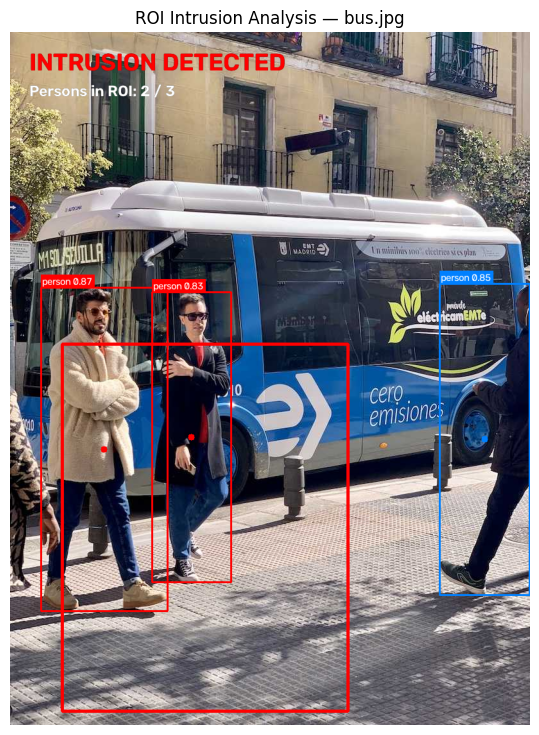

Saved: outputs/task6_roi_result.jpg


In [5]:
out = img.copy()

for p in person_report:
    x1, y1, x2, y2 = p["bbox"]
    cx, cy = p["centroid"]
    box_color = (0, 0, 255) if p["inside_roi"] else (255, 128, 0)

    cv2.rectangle(out, (x1, y1), (x2, y2), box_color, 2)
    cv2.circle(out, (cx, cy), 5, box_color, -1)

    label = f"person {p['conf']:.2f}"
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    cv2.rectangle(out, (x1, y1 - th - 6), (x1 + tw + 4, y1), box_color, -1)
    cv2.putText(out, label, (x1 + 2, y1 - 4),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)

roi_color = (0, 0, 255) if intrusion else (0, 255, 0)
cv2.polylines(out, [roi_pts], isClosed=True, color=roi_color, thickness=3)

status_text  = "INTRUSION DETECTED" if intrusion else "ROI CLEAR"
status_color = (0, 0, 255)             if intrusion else (0, 200, 0)
cv2.putText(out, status_text, (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 0, 0), 6, cv2.LINE_AA)
cv2.putText(out, status_text, (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.3, status_color, 3, cv2.LINE_AA)

summary = f"Persons in ROI: {sum(1 for p in person_report if p['inside_roi'])} / {len(person_report)}"
cv2.putText(out, summary, (30, 100), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4, cv2.LINE_AA)
cv2.putText(out, summary, (30, 100), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.title("ROI Intrusion Analysis — bus.jpg")
plt.axis("off")
plt.show()

cv2.imwrite("../outputs/task6_roi_result.jpg", out)
print("Saved: outputs/task6_roi_result.jpg")

In [6]:
import csv

with open("../outputs/task6_roi_report.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["person_index", "x1", "y1", "x2", "y2",
                "centroid_x", "centroid_y", "confidence",
                "inside_roi", "pointPolygonTest_distance"])
    for i, p in enumerate(person_report):
        x1, y1, x2, y2 = p["bbox"]
        cx, cy = p["centroid"]
        w.writerow([i, x1, y1, x2, y2, cx, cy, f"{p['conf']:.4f}",
                    p["inside_roi"], p["pointPolygonTest_dist"]])

print(open("../outputs/task6_roi_report.csv").read())

person_index,x1,y1,x2,y2,centroid_x,centroid_y,confidence,inside_roi,pointPolygonTest_distance
0,48,398,245,902,146,650,0.8657,True,1.0
1,669,392,809,877,739,634,0.8528,False,-1.0
2,221,405,344,857,282,631,0.8252,True,1.0



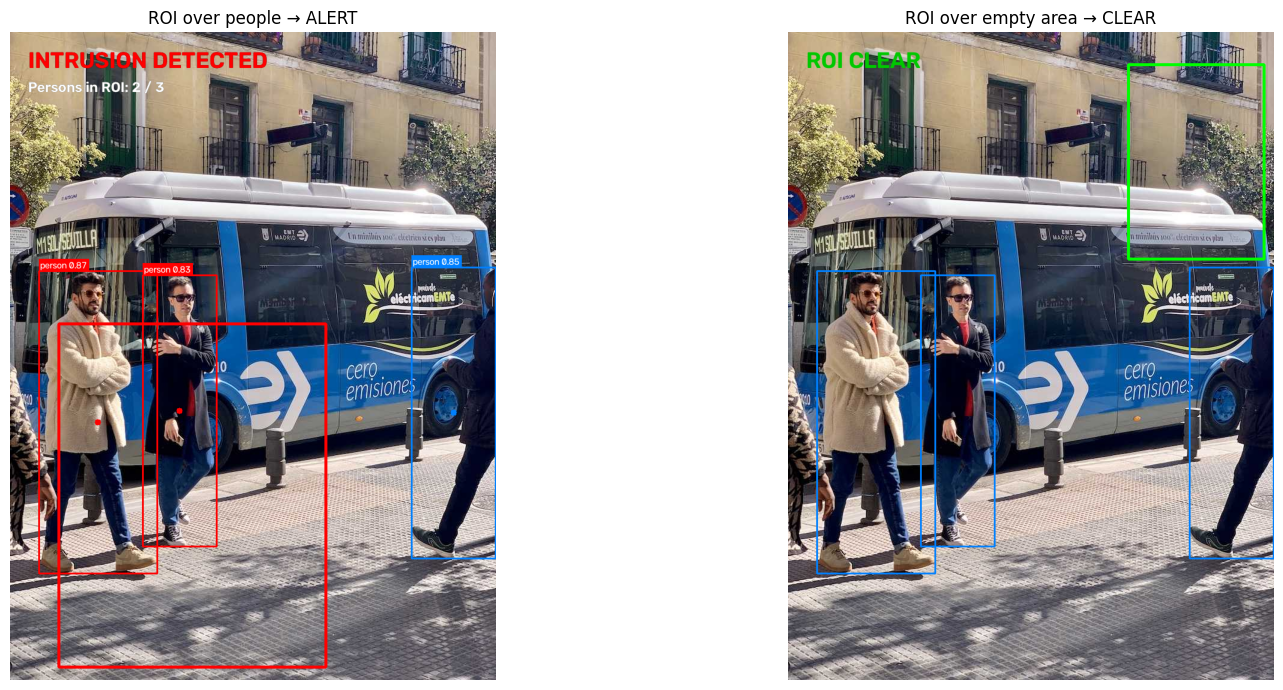

Saved: outputs/task6_comparison.png
Left ROI state:  INTRUSION
Right ROI state: CLEAR


In [7]:
roi_pts_clear = np.array([
    [int(W * 0.70), int(H * 0.05)],
    [int(W * 0.98), int(H * 0.05)],
    [int(W * 0.98), int(H * 0.35)],
    [int(W * 0.70), int(H * 0.35)],
], dtype=np.int32)

intrusion_clear = False
for p in person_report:
    cx, cy = p["centroid"]
    if cv2.pointPolygonTest(roi_pts_clear, (cx, cy), False) >= 0:
        intrusion_clear = True

out_clear = img.copy()
for p in person_report:
    x1, y1, x2, y2 = p["bbox"]
    cv2.rectangle(out_clear, (x1, y1), (x2, y2), (255, 128, 0), 2)
cv2.polylines(out_clear, [roi_pts_clear], isClosed=True, color=(0, 255, 0), thickness=3)
cv2.putText(out_clear, "ROI CLEAR" if not intrusion_clear else "INTRUSION DETECTED",
            (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 200, 0), 3, cv2.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"ROI over people → {'ALERT' if intrusion else 'CLEAR'}")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(out_clear, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"ROI over empty area → {'ALERT' if intrusion_clear else 'CLEAR'}")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("../outputs/task6_comparison.png", dpi=150)
plt.show()
print("Saved: outputs/task6_comparison.png")
print(f"Left ROI state:  {'INTRUSION' if intrusion else 'CLEAR'}")
print(f"Right ROI state: {'INTRUSION' if intrusion_clear else 'CLEAR'}")

SyntaxError: invalid syntax (2789139841.py, line 1)